# Comparaison des tokenizers : matrices de confusion

Ce notebook compare les 3 approches de tokenisation (Script 1 NLTK, Script 2 Regex v1, Script 3 Regex v2) en calculant des **matrices de confusion** au niveau des tokens.

- **Référence (ground truth)** : étiquettes au niveau caractères dérivées des positions des entités Départ/Arrivée dans la phrase.
- **Prédiction** : étiquettes BIO produites par chaque tokenizer + alignement.
- **Métriques** : précision, rappel, F1 et matrice de confusion par tokenizer.

## 1. Imports et chargement des tokenizers

In [3]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support,
    accuracy_score
)
import warnings
warnings.filterwarnings('ignore')

# Répertoire des scripts (notebook dans model/ALEXANDRE)
SCRIPT_DIR = os.getcwd()
if os.path.basename(SCRIPT_DIR) != 'ALEXANDRE':
    SCRIPT_DIR = os.path.join(os.path.dirname(SCRIPT_DIR), 'model', 'ALEXANDRE')
sys.path.insert(0, SCRIPT_DIR)

from script1_nltk_basic import tokenize_basic
from script2_regexp_basic import tokenize_regexp_basic
from script3_regexp_improved import tokenize_regexp_improved

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 8)

## 2. Chargement du dataset

In [4]:
def load_dataset(input_path: str, output_path: str, limit: int = None):
    """Charge dataset_input.txt et dataset_output.txt."""
    samples = []
    with open(input_path, 'r', encoding='utf-8') as f_in, \
         open(output_path, 'r', encoding='utf-8') as f_out:
        count = 0
        for input_line, output_line in zip(f_in, f_out):
            if limit and count >= limit:
                break
            parts_in = input_line.strip().split(',', 1)
            parts_out = output_line.strip().split(',')
            if len(parts_in) < 2 or len(parts_out) < 2:
                continue
            phrase = parts_in[1]
            depart = parts_out[1] if len(parts_out) > 1 else ""
            arrivee = parts_out[2] if len(parts_out) > 2 else ""
            if depart == "INVALID" or not depart or not arrivee:
                continue
            samples.append({"phrase": phrase, "depart": depart, "arrivee": arrivee})
            count += 1
    return samples


# Depuis model/ALEXANDRE le dataset est ../../dataset
_cwd = os.getcwd()
if 'ALEXANDRE' in _cwd:
    dataset_dir = os.path.normpath(os.path.join(_cwd, '..', '..', 'dataset'))
else:
    dataset_dir = os.path.normpath(os.path.join(_cwd, 'dataset'))

input_path = os.path.join(dataset_dir, 'dataset_input.txt')
output_path = os.path.join(dataset_dir, 'dataset_output.txt')
if not os.path.exists(input_path):
    raise FileNotFoundError(f'Dataset non trouvé: {input_path}')

N_SAMPLES = 2000  # Nombre de phrases pour la comparaison
data = load_dataset(input_path, output_path, limit=N_SAMPLES)
print(f"✅ {len(data)} phrases chargées")

✅ 2000 phrases chargées


## 3. Référence : étiquettes au niveau caractères

À partir des positions des entités Départ et Arrivée dans la phrase, on construit une séquence d'étiquettes par caractère (BIO), puis on projette sur les tokens de chaque tokenizer pour obtenir le **ground truth** par token.

In [5]:
def get_char_level_labels(phrase: str, depart: str, arrivee: str):
    """
    Construit les étiquettes BIO au niveau caractère.
    Retourne une liste de longueur len(phrase) : 'O', 'B-DEP', 'I-DEP', 'B-ARR', 'I-ARR'.
    """
    phrase_lower = phrase.lower()
    dep_lower = depart.lower().strip()
    arr_lower = arrivee.lower().strip()
    labels = ['O'] * len(phrase)
    
    def assign_span(start: int, end: int, prefix: str):
        if start < 0 or end > len(phrase):
            return
        labels[start] = f"B-{prefix}"
        for i in range(start + 1, end):
            labels[i] = f"I-{prefix}"
    
    # Recherche case-insensitive
    idx_dep = phrase_lower.find(dep_lower)
    if idx_dep != -1:
        assign_span(idx_dep, idx_dep + len(dep_lower), 'DEP')
    idx_arr = phrase_lower.find(arr_lower)
    if idx_arr != -1:
        assign_span(idx_arr, idx_arr + len(arr_lower), 'ARR')
    
    return labels


def get_token_spans(phrase: str, tokens: list):
    """
    Retourne les emplacements (start, end) en caractères pour chaque token dans la phrase.
    """
    phrase_lower = phrase.lower()
    spans = []
    current = 0
    for token in tokens:
        token_lower = token.lower()
        pos = phrase_lower.find(token_lower, current)
        if pos == -1:
            # Fallback: avancer caractère par caractère si token non trouvé (rare)
            spans.append((current, min(current + len(token), len(phrase))))
            current = min(current + len(token) + 1, len(phrase))
        else:
            spans.append((pos, pos + len(token)))
            current = pos + len(token)
    return spans


def tokens_to_true_labels(phrase: str, tokens: list, char_labels: list):
    """Associe à chaque token l'étiquette du premier caractère de son span."""
    spans = get_token_spans(phrase, tokens)
    return [char_labels[s[0]] if s[0] < len(char_labels) else 'O' for s in spans]

## 4. Alignement BIO pour chaque tokenizer

In [6]:
def align_labels(tokens: list, depart: str, arrivee: str, tokenize_fn):
    """Aligne les tokens avec les étiquettes BIO (prédiction du tokenizer)."""
    labels = ['O'] * len(tokens)
    dep_tokens = tokenize_fn(depart)
    arr_tokens = tokenize_fn(arrivee)
    tokens_lower = [t.lower() for t in tokens]
    dep_lower = [t.lower() for t in dep_tokens]
    arr_lower = [t.lower() for t in arr_tokens]
    
    for i in range(len(tokens_lower) - len(dep_lower) + 1):
        if tokens_lower[i:i+len(dep_lower)] == dep_lower:
            labels[i] = 'B-DEP'
            for j in range(1, len(dep_lower)):
                labels[i+j] = 'I-DEP'
            break
    for i in range(len(tokens_lower) - len(arr_lower) + 1):
        if tokens_lower[i:i+len(arr_lower)] == arr_lower:
            labels[i] = 'B-ARR'
            for j in range(1, len(arr_lower)):
                labels[i+j] = 'I-ARR'
            break
    return labels

## 5. Collecte des prédictions et ground truth par tokenizer

In [7]:
LABELS_ORDER = ['O', 'B-DEP', 'I-DEP', 'B-ARR', 'I-ARR']

def evaluate_tokenizer(data: list, tokenize_fn, name: str):
    """
    Pour chaque phrase : tokenise, calcule les vrais labels (ref caractères),
    et les labels prédits (alignement). Retourne y_true, y_pred et les métriques.
    """
    y_true, y_pred = [], []
    for sample in data:
        phrase = sample['phrase']
        depart = sample['depart']
        arrivee = sample['arrivee']
        char_labels = get_char_level_labels(phrase, depart, arrivee)
        tokens = tokenize_fn(phrase)
        if not tokens:
            continue
        true_labels = tokens_to_true_labels(phrase, tokens, char_labels)
        pred_labels = align_labels(tokens, depart, arrivee, tokenize_fn)
        # Même nombre de tokens
        n = len(tokens)
        y_true.extend(true_labels[:n])
        y_pred.extend(pred_labels[:n])
    
    return np.array(y_true), np.array(y_pred)


tokenizers = [
    (tokenize_basic, "Script 1 (NLTK)"),
    (tokenize_regexp_basic, "Script 2 (Regex v1)"),
    (tokenize_regexp_improved, "Script 3 (Regex v2)"),
]

results = {}
for tokenize_fn, name in tokenizers:
    y_true, y_pred = evaluate_tokenizer(data, tokenize_fn, name)
    results[name] = {'y_true': y_true, 'y_pred': y_pred}
    acc = accuracy_score(y_true, y_pred)
    print(f"{name}: {len(y_true)} tokens, accuracy = {acc:.4f}")

Script 1 (NLTK): 15675 tokens, accuracy = 0.9997
Script 2 (Regex v1): 18090 tokens, accuracy = 0.9396
Script 3 (Regex v2): 18350 tokens, accuracy = 0.9398


## 6. Matrices de confusion et métriques

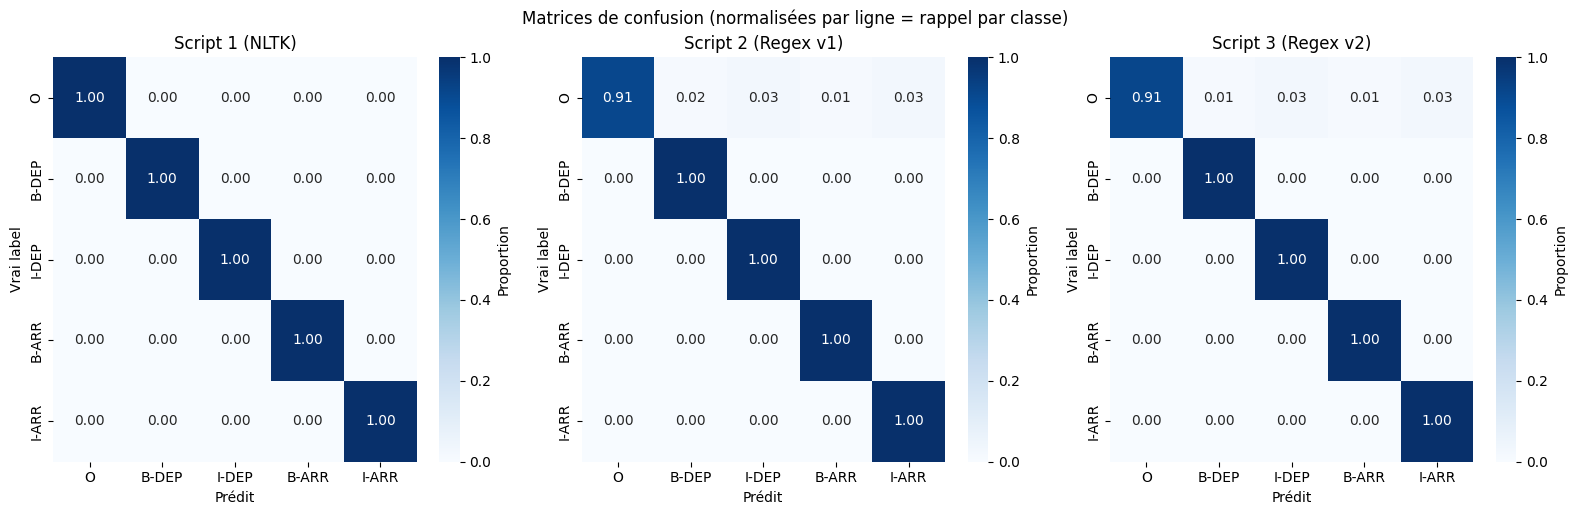

In [8]:
def plot_confusion_matrix(cm, labels_order, ax, title, normalize=True):
    if normalize:
        cm = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-10)
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd', cmap='Blues',
                xticklabels=labels_order, yticklabels=labels_order, ax=ax,
                cbar_kws={'label': 'Proportion' if normalize else 'Count'})
    ax.set_title(title)
    ax.set_ylabel('Vrai label')
    ax.set_xlabel('Prédit')


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(res['y_true'], res['y_pred'], labels=LABELS_ORDER)
    plot_confusion_matrix(cm, LABELS_ORDER, axes[idx], title=name, normalize=True)
plt.tight_layout()
plt.suptitle('Matrices de confusion (normalisées par ligne = rappel par classe)', y=1.02)
plt.show()

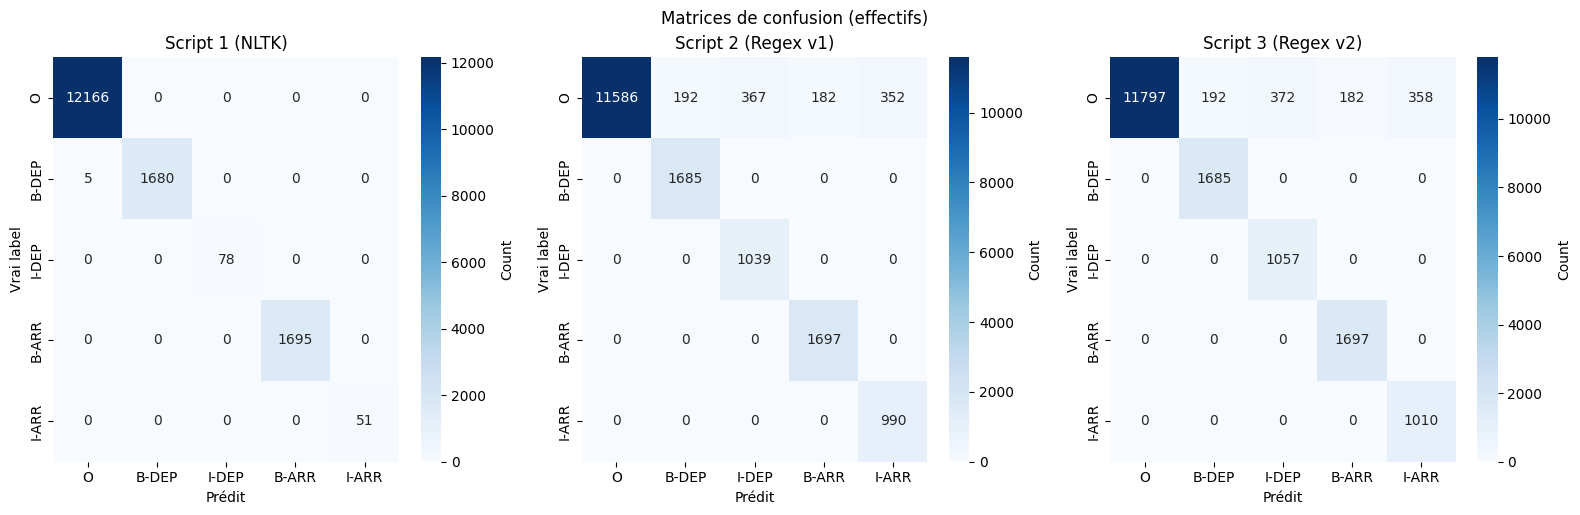

In [9]:
# Matrices en effectifs (non normalisées)
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 5))
for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(res['y_true'], res['y_pred'], labels=LABELS_ORDER)
    plot_confusion_matrix(cm, LABELS_ORDER, axes2[idx], title=name, normalize=False)
plt.tight_layout()
plt.suptitle('Matrices de confusion (effectifs)', y=1.02)
plt.show()

## 7. Rapports de classification (précision, rappel, F1)

In [10]:
for name, res in results.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(res['y_true'], res['y_pred'], labels=LABELS_ORDER, zero_division=0))
    print()

Script 1 (NLTK)
              precision    recall  f1-score   support

           O       1.00      1.00      1.00     12166
       B-DEP       1.00      1.00      1.00      1685
       I-DEP       1.00      1.00      1.00        78
       B-ARR       1.00      1.00      1.00      1695
       I-ARR       1.00      1.00      1.00        51

    accuracy                           1.00     15675
   macro avg       1.00      1.00      1.00     15675
weighted avg       1.00      1.00      1.00     15675


Script 2 (Regex v1)
              precision    recall  f1-score   support

           O       1.00      0.91      0.95     12679
       B-DEP       0.90      1.00      0.95      1685
       I-DEP       0.74      1.00      0.85      1039
       B-ARR       0.90      1.00      0.95      1697
       I-ARR       0.74      1.00      0.85       990

    accuracy                           0.94     18090
   macro avg       0.86      0.98      0.91     18090
weighted avg       0.95      0.94      0

## 8. Synthèse comparative

,Tokenizer,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted)
0,Script 1 (NLTK),0.999681,0.999681,0.999681,0.999681
1,Script 2 (Regex v1),0.939580,0.952039,0.939580,0.941752
2,Script 3 (Regex v2),0.939837,0.952250,0.939837,0.942012


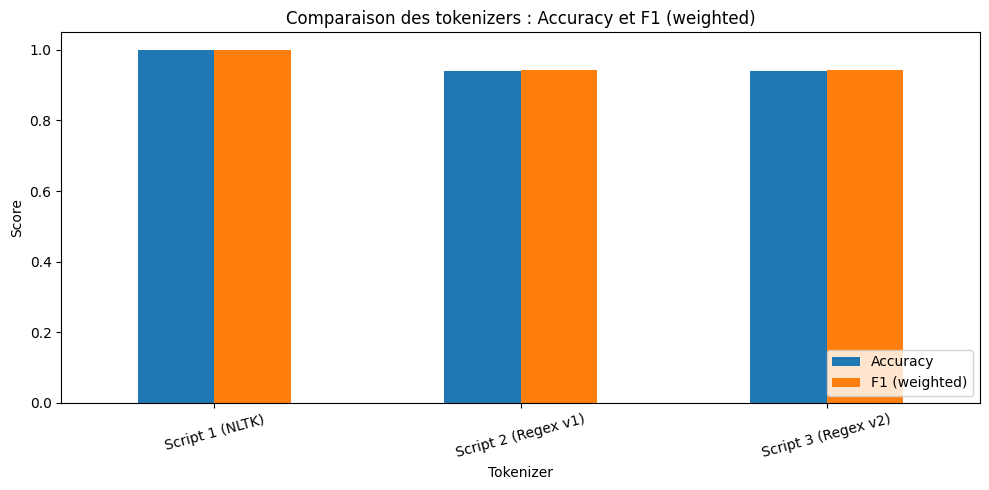

In [11]:
summary = []
for name, res in results.items():
    acc = accuracy_score(res['y_true'], res['y_pred'])
    p, r, f1, _ = precision_recall_fscore_support(
        res['y_true'], res['y_pred'], labels=LABELS_ORDER, average='weighted', zero_division=0
    )
    summary.append({
        'Tokenizer': name,
        'Accuracy': acc,
        'Precision (weighted)': p,
        'Recall (weighted)': r,
        'F1 (weighted)': f1
    })

import pandas as pd
df_summary = pd.DataFrame(summary)
display(df_summary)

df_summary.plot(x='Tokenizer', y=['Accuracy', 'F1 (weighted)'], kind='bar', figsize=(10, 5))
plt.xticks(rotation=15)
plt.ylabel('Score')
plt.title('Comparaison des tokenizers : Accuracy et F1 (weighted)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()